In [1]:

import os
from pathlib import Path
import scanpy as sc
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import scipy as sp

# Marker genes overlap

In [50]:
#rosmap = sc.read_h5ad(r"C:\Users\gabri\Documents\Data_projects\MCcharactertization\ROSMAP\_core_data\scanpy\Astrocytes.h5ad")
rosmap = sc.read_h5ad('/Users/ga0028vi/Documents/MCcharactertization/ROSMAP/_core_data/scanpy/Astrocytes.h5ad')

In [51]:
rosmap.obs['projid'] = rosmap.obs['projid'].astype(str)
rosmap.obs['newdons'] = rosmap.obs['projid']
rosmap.obs['cellsubtypes'] = rosmap.obs['cell_type_high_resolution']
rosmap.obs['cellsubtypes'] = rosmap.obs['cellsubtypes'].str.replace('_', '', regex=True)
rosmap.X = rosmap.layers['counts']

In [52]:
#seaad = sc.read_h5ad(r"C:\Users\gabri\Documents\Data_projects\MCcharactertization\SEAAD_PFC\_core_data\SEAAD_PFC_finalnuclei_Astrocytes.h5ad")
seaad = sc.read_h5ad('/Users/ga0028vi/Documents/MCcharactertization/SEAAD_PFC/_core_data/SEAAD_PFC_finalnuclei_Astrocytes.h5ad')

In [53]:
seaad.obs['Donor ID'] = seaad.obs['Donor ID'].astype(str)
seaad.obs['Donor ID'] = seaad.obs['Donor ID'].str.replace('.', '')

In [55]:
### SEAAD cleanup
cols_to_drop = ['Race (choice=White)',
 'Race (choice=Black/ African American)',
 'Race (choice=Asian)',
 'Race (choice=American Indian/ Alaska Native)',
 'Race (choice=Native Hawaiian or Pacific Islander)',
 'Race (choice=Unknown or unreported)',
 'Race (choice=Other)',
 'specify other race',
 'Hispanic/Latino',
 'Highest level of education',
 'Years of education',
 'PMI',
 'Fresh Brain Weight',
 'Brain pH',
 'Overall AD neuropathological Change',
 'Thal',
 'Braak',
 'CERAD score',
 'Overall CAA Score',
 'Highest Lewy Body Disease',
 'Total Microinfarcts (not observed grossly)',
 'Total microinfarcts in screening sections',
 'Atherosclerosis',
 'Arteriolosclerosis',
 'LATE',
 'Cognitive Status',
 'Last CASI Score',
 'Interval from last CASI in months',
 'Last MMSE Score',
 'Interval from last MMSE in months',
 'Last MOCA Score',
 'Interval from last MOCA in months',
 'APOE Genotype',
 'Primary Study Name',
 'Secondary Study Name',
 'NeuN positive fraction on FANS',
 'RIN',
 'cell_prep_type',
 'facs_population_plan',
 'rna_amplification',
 'sample_name',
 'sample_quantity_count',
 'expc_cell_capture',
 'method',
 'pcr_cycles',
 'percent_cdna_longer_than_400bp',
 'rna_amplification_pass_fail',
 'amplified_quantity_ng',
 'load_name',
 'library_prep',
 'library_input_ng',
 'r1_index',
 'avg_size_bp',
 'quantification_fmol',
 'library_prep_pass_fail',
 'exp_component_vendor_name',
 'batch_vendor_name',
 'experiment_component_failed',
 'alignment',
 'Genome',
 'ar_id',
 'bc',
 'GEX_Estimated_number_of_cells',
 'GEX_number_of_reads',
 'GEX_sequencing_saturation',
 'GEX_Mean_raw_reads_per_cell',
 'GEX_Q30_bases_in_barcode',
 'GEX_Q30_bases_in_read_2',
 'GEX_Q30_bases_in_UMI',
 'GEX_Percent_duplicates',
 'GEX_Q30_bases_in_sample_index_i1',
 'GEX_Q30_bases_in_sample_index_i2',
 'GEX_Reads_with_TSO',
 'GEX_Sequenced_read_pairs',
 'GEX_Valid_UMIs',
 'GEX_Valid_barcodes',
 'GEX_Reads_mapped_to_genome',
 'GEX_Reads_mapped_confidently_to_genome',
 'GEX_Reads_mapped_confidently_to_intergenic_regions',
 'GEX_Reads_mapped_confidently_to_intronic_regions',
 'GEX_Reads_mapped_confidently_to_exonic_regions',
 'GEX_Reads_mapped_confidently_to_transcriptome',
 'GEX_Reads_mapped_antisense_to_gene',
 'GEX_Fraction_of_transcriptomic_reads_in_cells',
 'GEX_Total_genes_detected',
 'GEX_Median_UMI_counts_per_cell',
 'GEX_Median_genes_per_cell',
 'Multiome_Feature_linkages_detected',
 'Multiome_Linked_genes',
 'Multiome_Linked_peaks',
 'ATAC_Confidently_mapped_read_pairs',
 'ATAC_Fraction_of_genome_in_peaks',
 'ATAC_Fraction_of_high_quality_fragments_in_cells',
 'ATAC_Fraction_of_high_quality_fragments_overlapping_TSS',
 'ATAC_Fraction_of_high_quality_fragments_overlapping_peaks',
 'ATAC_Fraction_of_transposition_events_in_peaks_in_cells',
 'ATAC_Mean_raw_read_pairs_per_cell',
 'ATAC_Median_high_quality_fragments_per_cell',
 'ATAC_Non-nuclear_read_pairs',
 'ATAC_Number_of_peaks',
 'ATAC_Percent_duplicates',
 'ATAC_Q30_bases_in_barcode',
 'ATAC_Q30_bases_in_read_1',
 'ATAC_Q30_bases_in_read_2',
 'ATAC_Q30_bases_in_sample_index_i1',
 'ATAC_Sequenced_read_pairs',
 'ATAC_TSS_enrichment_score',
 'ATAC_Unmapped_read_pairs',
 'ATAC_Valid_barcodes',
 'Number of mapped reads',
 'Number of unmapped reads',
 'Number of multimapped reads',
 'Number of reads',
 'Number of UMIs',
 'Genes detected',
 'Doublet score',
 'Fraction mitochondrial UMIs',
 'Used in analysis',
 'Class confidence',
 'Class',
 'Subclass confidence','Supertype confidence',
 'Supertype (non-expanded)','Continuous Pseudo-progression Score','Organism','Neurotypical reference',
 'Brain Region', 'Sex', 'Gender', 'Age at Death',
 'Severely Affected Donor']
seaad.obs = seaad.obs.drop(columns=cols_to_drop, errors="ignore")
del seaad.uns
del seaad.obsm
del seaad.obsp

seaad.X = seaad.layers['UMIs']
#seaad.obs["major_cell_type"] = "OPC"
seaad.obs["cellsubtypes"] = seaad.obs['Supertype']
seaad.obs['newdons'] = seaad.obs['Donor ID']

In [56]:
# common genes
genes = rosmap.var_names.intersection(seaad.var_names)
seaad = seaad[:, genes]
rosmap = rosmap[:, genes]

### Look for marker genes in groups

#### ROSMAP

In [57]:
# Normalizing to median total counts
sc.pp.normalize_total(rosmap)
# Logarithmize the data
sc.pp.log1p(rosmap)

/opt/anaconda3/envs/SEAADpy/lib/python3.12/site-packages/scanpy/preprocessing/_normalization.py:206: UserWarning: Received a view of an AnnData. Making a copy.
  view_to_actual(adata)


In [58]:
rosmap

AnnData object with n_obs × n_vars = 149558 × 31908
    obs: 'projid', 'cell_type_high_resolution', 'newdons', 'cellsubtypes'
    uns: 'log1p'
    layers: 'counts'

In [59]:
sc.tl.rank_genes_groups(rosmap, groupby="cellsubtypes", method="wilcoxon")

In [60]:
sc.tl.filter_rank_genes_groups(
    rosmap,
    key="rank_genes_groups",
    key_added="rank_genes_groups_filtered"
)

         Falling back to preprocessing with `sc.pp.pca` and default params.


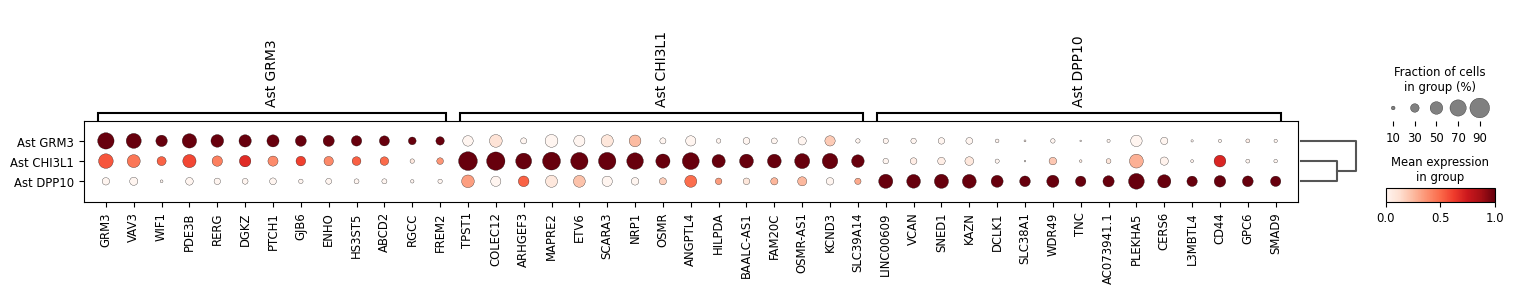

In [61]:
sc.pl.rank_genes_groups_dotplot(
    rosmap,
    groupby="cellsubtypes",
    key="rank_genes_groups_filtered",
    n_genes=15,
    standard_scale="var"
)


In [62]:
Astdf = sc.get.rank_genes_groups_df(
    rosmap,
    group="Ast GRM3",
    key="rank_genes_groups_filtered"
)

In [63]:
Astdf

,names,scores,logfoldchanges,pvals,pvals_adj
0,NaN,157.959869,1.242651,0.0,0.0
1,NaN,146.152512,0.893061,0.0,0.0
2,NaN,142.970291,0.695878,0.0,0.0
3,NaN,142.357849,0.686467,0.0,0.0
4,NaN,136.054993,1.563899,0.0,0.0
...,...,...,...,...,...
31903,NaN,-125.924980,-3.688919,0.0,0.0
31904,NaN,-128.175705,-1.961356,0.0,0.0
31905,NaN,-143.407410,-0.732001,0.0,0.0
31906,NaN,-169.995346,-1.806162,0.0,0.0


#### SEAAD

In [64]:
# Normalizing to median total counts
sc.pp.normalize_total(seaad)
# Logarithmize the data
sc.pp.log1p(seaad)

/opt/anaconda3/envs/SEAADpy/lib/python3.12/site-packages/scanpy/preprocessing/_normalization.py:206: UserWarning: Received a view of an AnnData. Making a copy.
  view_to_actual(adata)


In [65]:
sc.tl.rank_genes_groups(seaad, groupby="cellsubtypes", method="wilcoxon")

sc.tl.filter_rank_genes_groups(
    seaad,
    key="rank_genes_groups",
    key_added="rank_genes_groups_filtered"
)

         Falling back to preprocessing with `sc.pp.pca` and default params.


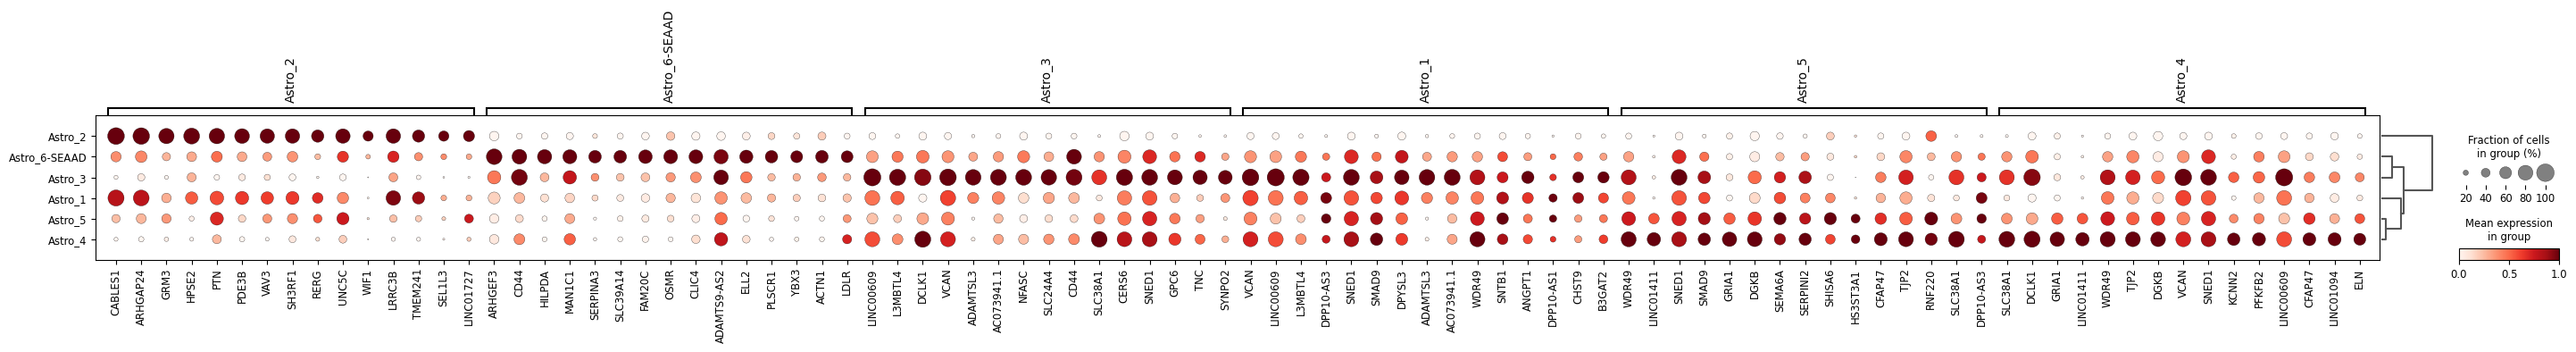

In [66]:
sc.pl.rank_genes_groups_dotplot(
    seaad,
    groupby="cellsubtypes",
    key="rank_genes_groups_filtered",
    n_genes=15,
    standard_scale="var"
)

In [140]:
n_top=100
groups = (
    list(rosmap.obs['cellsubtypes'].cat.categories)
)

rosmap_markers = {}
for g in groups:
    df = sc.get.rank_genes_groups_df(rosmap, group=g, key='rank_genes_groups_filtered')

    # filter_rank_genes_groups keeps rows but sets names to NA -> drop them
    df = df.dropna(subset=["names"]).head(n_top).copy()

    rosmap_markers[g] = df


In [141]:
groups = (
    list(seaad.obs['cellsubtypes'].cat.categories)
)

seaad_markers = {}
for g in groups:
    df = sc.get.rank_genes_groups_df(seaad, group=g, key='rank_genes_groups_filtered')

    # filter_rank_genes_groups keeps rows but sets names to NA -> drop them
    df = df.dropna(subset=["names"]).head(n_top).copy()

    seaad_markers[g] = df


In [142]:
# make sure your keys are in a stable order
ros_groups = list(rosmap_markers.keys())
sea_groups = list(seaad_markers.keys())

overlap = pd.DataFrame(index=ros_groups, columns=sea_groups, dtype=int)

for r_sub in ros_groups:
    r_genes = set(rosmap_markers[r_sub]["names"])
    for s_sub in sea_groups:
        s_genes = set(seaad_markers[s_sub]["names"])
        overlap.loc[r_sub, s_sub] = len(r_genes & s_genes)

overlap

,Astro_1,Astro_2,Astro_6-SEAAD,Astro_5,Astro_3,Astro_4
Ast CHI3L1,0.0,9.0,37.0,1.0,4.0,2.0
Ast DPP10,16.0,0.0,20.0,20.0,49.0,40.0
Ast GRM3,0.0,12.0,0.0,0.0,0.0,0.0


In [143]:
overlap_norm_ntop = overlap / n_top

# max possible overlap per pair is min(#genes_in_ros, #genes_in_sea)
ros_sizes = pd.Series({k: len(set(v["names"])) for k, v in rosmap_markers.items()})
sea_sizes = pd.Series({k: len(set(v["names"])) for k, v in seaad_markers.items()})

denom = pd.DataFrame(index=ros_groups, columns=sea_groups, dtype=float)
for r_sub in ros_groups:
    for s_sub in sea_groups:
        denom.loc[r_sub, s_sub] = min(ros_sizes[r_sub], sea_sizes[s_sub])

overlap_norm_maxpossible = overlap / denom


In [144]:
overlap_norm_maxpossible

,Astro_1,Astro_2,Astro_6-SEAAD,Astro_5,Astro_3,Astro_4
Ast CHI3L1,0.000000,0.090000,0.370000,0.015152,0.040000,0.020000
Ast DPP10,0.695652,0.000000,0.273973,0.303030,0.671233,0.547945
Ast GRM3,0.000000,0.923077,0.000000,0.000000,0.000000,0.000000


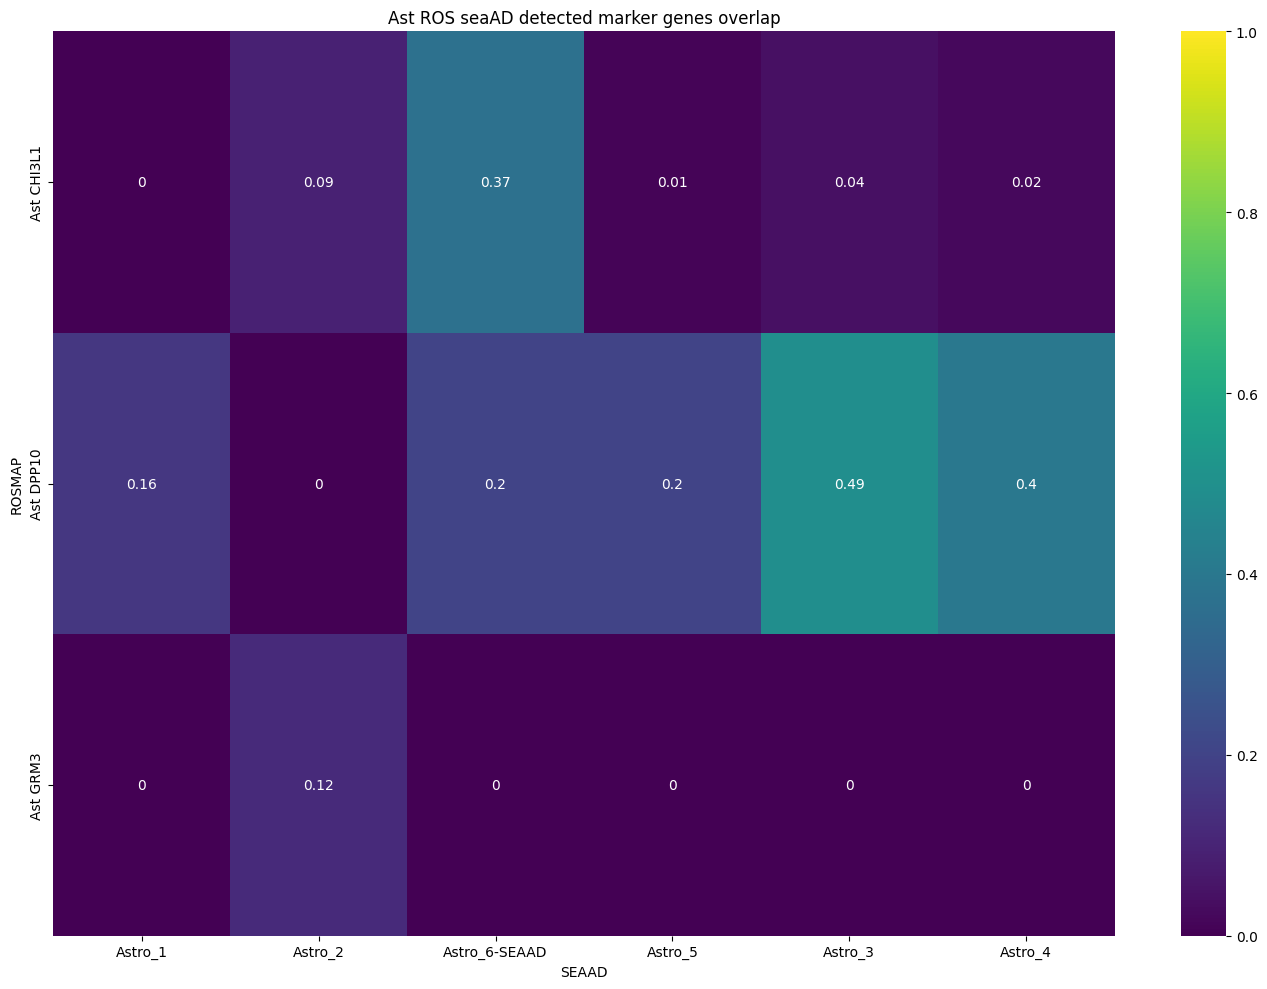

In [145]:
plt.figure(figsize=(14,10))
sns.heatmap(overlap_norm_ntop, cmap="viridis", vmin=0, vmax=1, annot=True)
plt.title("Ast ROS seaAD detected marker genes overlap")
plt.xlabel("SEAAD")
plt.ylabel("ROSMAP")
plt.tight_layout()
plt.show()


In [ ]:
breakp

# Similarity calc no batcgh corr

In [7]:
#rosmap = sc.read_h5ad(r"C:\Users\gabri\Documents\Data_projects\MCcharactertization\ROSMAP\_core_data\scanpy\Astrocytes.h5ad")
rosmap = sc.read_h5ad('/Users/ga0028vi/Documents/MCcharactertization/ROSMAP/_core_data/scanpy/Astrocytes.h5ad')

rosmap.obs['projid'] = rosmap.obs['projid'].astype(str)
rosmap.obs['newdons'] = rosmap.obs['projid']
rosmap.obs['cellsubtypes'] = rosmap.obs['cell_type_high_resolution']
rosmap.obs['cellsubtypes'] = rosmap.obs['cellsubtypes'].str.replace('_', '', regex=True)
rosmap.X = rosmap.layers['counts']

#seaad = sc.read_h5ad(r"C:\Users\gabri\Documents\Data_projects\MCcharactertization\SEAAD_PFC\_core_data\SEAAD_PFC_finalnuclei_Astrocytes.h5ad")
seaad = sc.read_h5ad('/Users/ga0028vi/Documents/MCcharactertization/SEAAD_PFC/_core_data/SEAAD_PFC_finalnuclei_Astrocytes.h5ad')

seaad.obs['Donor ID'] = seaad.obs['Donor ID'].astype(str)
seaad.obs['Donor ID'] = seaad.obs['Donor ID'].str.replace('.', '')

### SEAAD cleanup
cols_to_drop = ['Race (choice=White)',
 'Race (choice=Black/ African American)',
 'Race (choice=Asian)',
 'Race (choice=American Indian/ Alaska Native)',
 'Race (choice=Native Hawaiian or Pacific Islander)',
 'Race (choice=Unknown or unreported)',
 'Race (choice=Other)',
 'specify other race',
 'Hispanic/Latino',
 'Highest level of education',
 'Years of education',
 'PMI',
 'Fresh Brain Weight',
 'Brain pH',
 'Overall AD neuropathological Change',
 'Thal',
 'Braak',
 'CERAD score',
 'Overall CAA Score',
 'Highest Lewy Body Disease',
 'Total Microinfarcts (not observed grossly)',
 'Total microinfarcts in screening sections',
 'Atherosclerosis',
 'Arteriolosclerosis',
 'LATE',
 'Cognitive Status',
 'Last CASI Score',
 'Interval from last CASI in months',
 'Last MMSE Score',
 'Interval from last MMSE in months',
 'Last MOCA Score',
 'Interval from last MOCA in months',
 'APOE Genotype',
 'Primary Study Name',
 'Secondary Study Name',
 'NeuN positive fraction on FANS',
 'RIN',
 'cell_prep_type',
 'facs_population_plan',
 'rna_amplification',
 'sample_name',
 'sample_quantity_count',
 'expc_cell_capture',
 'method',
 'pcr_cycles',
 'percent_cdna_longer_than_400bp',
 'rna_amplification_pass_fail',
 'amplified_quantity_ng',
 'load_name',
 'library_prep',
 'library_input_ng',
 'r1_index',
 'avg_size_bp',
 'quantification_fmol',
 'library_prep_pass_fail',
 'exp_component_vendor_name',
 'batch_vendor_name',
 'experiment_component_failed',
 'alignment',
 'Genome',
 'ar_id',
 'bc',
 'GEX_Estimated_number_of_cells',
 'GEX_number_of_reads',
 'GEX_sequencing_saturation',
 'GEX_Mean_raw_reads_per_cell',
 'GEX_Q30_bases_in_barcode',
 'GEX_Q30_bases_in_read_2',
 'GEX_Q30_bases_in_UMI',
 'GEX_Percent_duplicates',
 'GEX_Q30_bases_in_sample_index_i1',
 'GEX_Q30_bases_in_sample_index_i2',
 'GEX_Reads_with_TSO',
 'GEX_Sequenced_read_pairs',
 'GEX_Valid_UMIs',
 'GEX_Valid_barcodes',
 'GEX_Reads_mapped_to_genome',
 'GEX_Reads_mapped_confidently_to_genome',
 'GEX_Reads_mapped_confidently_to_intergenic_regions',
 'GEX_Reads_mapped_confidently_to_intronic_regions',
 'GEX_Reads_mapped_confidently_to_exonic_regions',
 'GEX_Reads_mapped_confidently_to_transcriptome',
 'GEX_Reads_mapped_antisense_to_gene',
 'GEX_Fraction_of_transcriptomic_reads_in_cells',
 'GEX_Total_genes_detected',
 'GEX_Median_UMI_counts_per_cell',
 'GEX_Median_genes_per_cell',
 'Multiome_Feature_linkages_detected',
 'Multiome_Linked_genes',
 'Multiome_Linked_peaks',
 'ATAC_Confidently_mapped_read_pairs',
 'ATAC_Fraction_of_genome_in_peaks',
 'ATAC_Fraction_of_high_quality_fragments_in_cells',
 'ATAC_Fraction_of_high_quality_fragments_overlapping_TSS',
 'ATAC_Fraction_of_high_quality_fragments_overlapping_peaks',
 'ATAC_Fraction_of_transposition_events_in_peaks_in_cells',
 'ATAC_Mean_raw_read_pairs_per_cell',
 'ATAC_Median_high_quality_fragments_per_cell',
 'ATAC_Non-nuclear_read_pairs',
 'ATAC_Number_of_peaks',
 'ATAC_Percent_duplicates',
 'ATAC_Q30_bases_in_barcode',
 'ATAC_Q30_bases_in_read_1',
 'ATAC_Q30_bases_in_read_2',
 'ATAC_Q30_bases_in_sample_index_i1',
 'ATAC_Sequenced_read_pairs',
 'ATAC_TSS_enrichment_score',
 'ATAC_Unmapped_read_pairs',
 'ATAC_Valid_barcodes',
 'Number of mapped reads',
 'Number of unmapped reads',
 'Number of multimapped reads',
 'Number of reads',
 'Number of UMIs',
 'Genes detected',
 'Doublet score',
 'Fraction mitochondrial UMIs',
 'Used in analysis',
 'Class confidence',
 'Class',
 'Subclass confidence','Supertype confidence',
 'Supertype (non-expanded)','Continuous Pseudo-progression Score','Organism','Neurotypical reference',
 'Brain Region', 'Sex', 'Gender', 'Age at Death',
 'Severely Affected Donor']
seaad.obs = seaad.obs.drop(columns=cols_to_drop, errors="ignore")
del seaad.uns
del seaad.obsm
del seaad.obsp

seaad.X = seaad.layers['UMIs']
#seaad.obs["major_cell_type"] = "OPC"
seaad.obs["cellsubtypes"] = seaad.obs['Supertype']
seaad.obs['newdons'] = seaad.obs['Donor ID']


In [8]:
sc.pp.filter_cells(rosmap, min_genes=100)
sc.pp.filter_genes(rosmap, min_cells=3) 
sc.pp.filter_cells(seaad, min_genes=100)
sc.pp.filter_genes(seaad, min_cells=3)

# common genes
genes = rosmap.var_names.intersection(seaad.var_names)
seaad = seaad[:, genes]
rosmap = rosmap[:, genes]

In [9]:
# Normalizing and logtransform 
sc.pp.normalize_total(rosmap)
sc.pp.log1p(rosmap)
sc.pp.normalize_total(seaad)
sc.pp.log1p(seaad)

/opt/anaconda3/envs/label_transfer/lib/python3.12/site-packages/scanpy/preprocessing/_normalization.py:269: UserWarning: Received a view of an AnnData. Making a copy.
  view_to_actual(adata)


In [17]:
rosmap.obs['cellsubtypes'] = rosmap.obs['cellsubtypes'].str.replace(' ', '', regex=True)

pseudobulk_means_list = []

groups = rosmap.obs.groupby(["newdons", "cellsubtypes"]).groups  # (donor, subtype) -> row indices

for (donor, subtype), idx in groups.items():
    subset_name = f"{donor}_{subtype}"

    # subset AnnData
    sub = rosmap[idx].copy()

    # build expression df (cells x genes)
    X = sub.X.toarray() if sp.sparse.issparse(sub.X) else np.asarray(sub.X)
    expr_df = pd.DataFrame(X, index=sub.obs_names, columns=sub.var_names)

    # one label for ALL cells in this donor×subtype subset
    labels = pd.Series(subset_name, index=sub.obs_names, dtype="object")

    # mean expression for this one pseudobulk
    mean_expr = expr_df.groupby(labels).mean()  # results in a 1-row DF indexed by subset_name
    pseudobulk_means_list.append(mean_expr)

    del sub

pseudobulk_df = pd.concat(pseudobulk_means_list, axis=0)
pseudobulk_df.index.name = "metacell"

In [19]:
pseudobulk_df

,MIR1302-2HG,AL627309.1,AL627309.2,AC114498.1,AL669831.2,FAM87B,LINC00115,FAM41C,AL645608.7,AL645608.1,...,AC011841.1,AC011043.1,AC011043.2,AL592183.1,AC007325.1,AC007325.4,AC007325.2,AL354822.1,AC023491.2,AC240274.1
metacell,,,,,,,,,,,,,,,,,,,,,
10100574_AstCHI3L1,0.0,0.000000,0.0,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.031571,0.000000,0.220417,0.0,0.000000,0.049584,0.000000,0.0,0.014702
10100574_AstDPP10,0.0,0.009134,0.0,0.000000,0.0,0.000000,0.005082,0.000000,0.002474,0.003342,...,0.000000,0.042049,0.000000,0.101646,0.0,0.012570,0.056466,0.042568,0.0,0.013723
10100574_AstGRM3,0.0,0.009979,0.0,0.000860,0.0,0.000000,0.004733,0.001051,0.002393,0.000000,...,0.000000,0.039748,0.000000,0.172457,0.0,0.019158,0.070096,0.041618,0.0,0.017924
10100862_AstCHI3L1,0.0,0.000000,0.0,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.064813,0.0,0.000000,0.272732,0.075410,0.0,0.123223
10100862_AstDPP10,0.0,0.015576,0.0,0.001813,0.0,0.000000,0.003956,0.000000,0.006993,0.026489,...,0.000000,0.026402,0.005745,0.177575,0.0,0.008653,0.070590,0.023808,0.0,0.019767
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9841821_AstDPP10,0.0,0.000000,0.0,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.030211,...,0.042908,0.000000,0.000000,0.138313,0.0,0.119580,0.131147,0.075510,0.0,0.042908
9841821_AstGRM3,0.0,0.010915,0.0,0.001643,0.0,0.003424,0.004530,0.002454,0.005715,0.000000,...,0.002090,0.018079,0.000000,0.122307,0.0,0.023459,0.076443,0.030721,0.0,0.018097
98953007_AstCHI3L1,0.0,0.000000,0.0,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.247409,0.0,0.110982,0.000000,0.000000,0.0,0.000000


In [105]:
### ROSMAP pseudobulk
X = rosmap.X
if not sp.sparse.issparse(rosmap.X):
    rosmap.X = sp.csr_matrix(rosmap.X)

# group codes for subtypes
rosmap.obs['cellsubtypes'] = rosmap.obs['cellsubtypes'].str.replace(' ', '', regex=True)

sub = rosmap.obs["cellsubtypes"].astype("category")
codes = sub.cat.codes.values
levels = list(sub.cat.categories)

n_cells = rosmap.n_obs
n_groups = len(levels)

# indicator matrix: cell -> group
G = sp.sparse.csr_matrix(
    (np.ones(n_cells, dtype=np.float32), (codes, np.arange(n_cells))),
    shape=(n_groups, n_cells)
)

# sums per group (groups x genes), still sparse-ish
sums = G @ rosmap.X

# divide by group sizes to get means
sizes = np.asarray(G.sum(axis=1)).ravel()
means = sums.multiply(1.0 / sizes[:, None])

# convert to a DataFrame (this WILL be dense, but now it's only n_groups x n_genes)
ros_pb = pd.DataFrame(means.toarray(), index=levels, columns=genes)

In [106]:
### SEAAD pseudobulk

X = seaad.X
if not sp.sparse.issparse(X):
    X = sp.csr_matrix(X)

# group codes for subtypes
sub = seaad.obs["cellsubtypes"].astype("category")
codes = sub.cat.codes.values
levels = list(sub.cat.categories)

n_cells = seaad.n_obs
n_groups = len(levels)

# indicator matrix: cell -> group
G = sp.sparse.csr_matrix(
    (np.ones(n_cells, dtype=np.float32), (codes, np.arange(n_cells))),
    shape=(n_groups, n_cells)
)

# sums per group (groups x genes), still sparse-ish
sums = G @ X

# divide by group sizes to get means
sizes = np.asarray(G.sum(axis=1)).ravel()
means = sums.multiply(1.0 / sizes[:, None])

# convert to a DataFrame (this WILL be dense, but now it's only n_groups x n_genes)
sea_pb = pd.DataFrame(means.toarray(), index=levels, columns=genes)

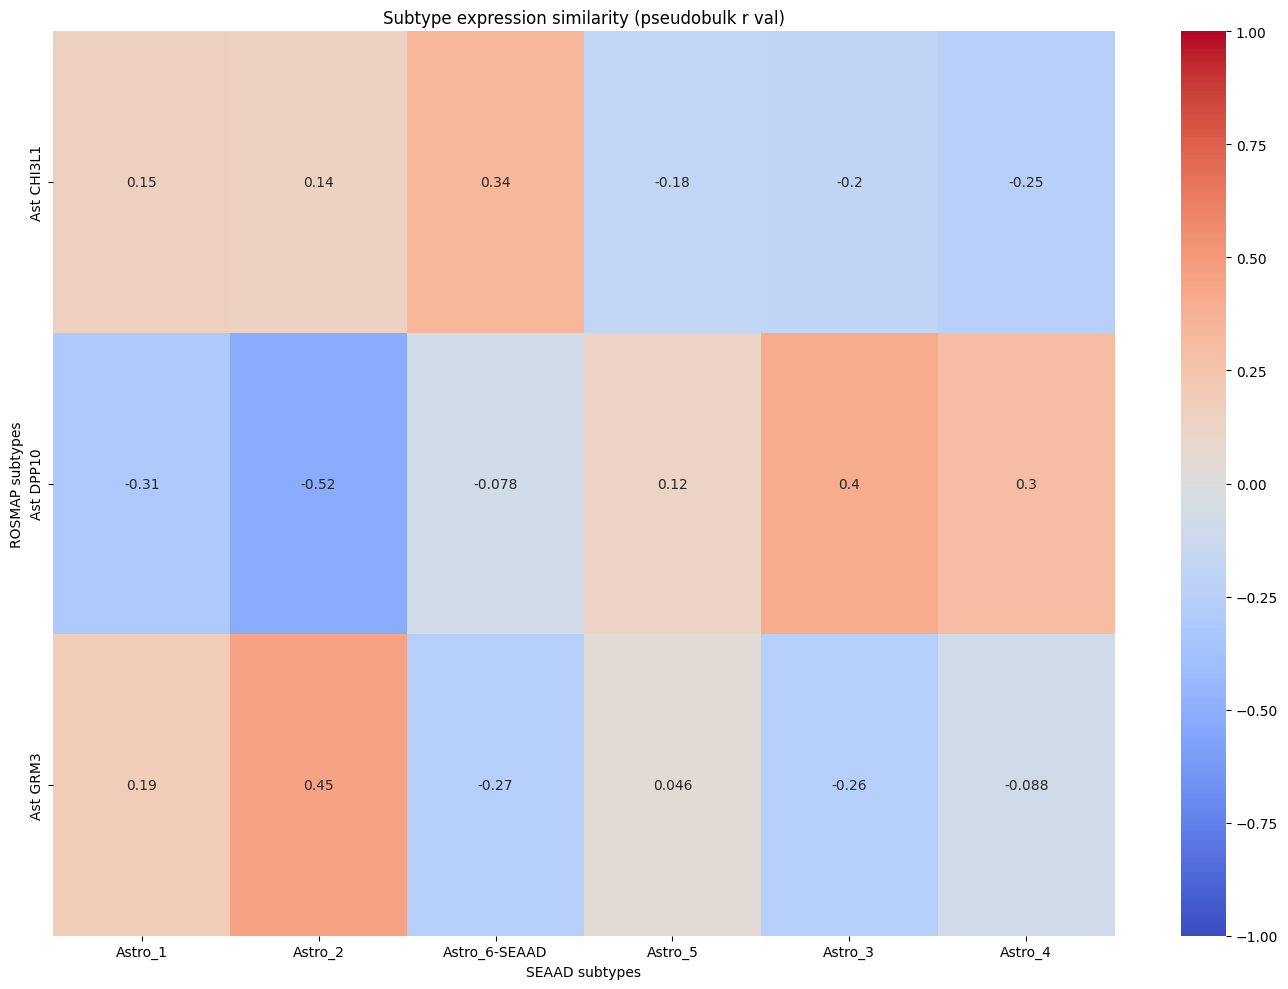

In [107]:
### ALL GENES corr
from sklearn.preprocessing import StandardScaler

ros_z = pd.DataFrame(
    StandardScaler().fit_transform(ros_pb),
    index=ros_pb.index,
    columns=ros_pb.columns,
)

sea_z = pd.DataFrame(
    StandardScaler().fit_transform(sea_pb),
    index=sea_pb.index,
    columns=sea_pb.columns,
)

expr_sim = pd.DataFrame(
    index=ros_z.index,
    columns=sea_z.index,
    dtype=float
)

for r in ros_z.index:
    for s in sea_z.index:
        expr_sim.loc[r, s] = np.corrcoef(
            ros_z.loc[r].values,
            sea_z.loc[s].values
        )[0, 1]
        
plt.figure(figsize=(14,10))
sns.heatmap(expr_sim, vmin=-1, vmax=1, cmap="coolwarm", annot=True)
plt.xlabel("SEAAD subtypes")
plt.ylabel("ROSMAP subtypes")
plt.title("Subtype expression similarity (pseudobulk r val)")
plt.tight_layout()
plt.show()

In [117]:
### Select and sub  HVGs
sc.pp.highly_variable_genes(rosmap, n_top_genes = 10)
### Select and sub  HVGs
sc.pp.highly_variable_genes(seaad, n_top_genes = 10)

# Subset BOTH rosmap and seaad HVGs
hvg = rosmap.var_names[rosmap.var["highly_variable"]].union(
      seaad.var_names[seaad.var["highly_variable"]]
)
rosmap = rosmap[:, hvg].copy()
seaad  = seaad[:, hvg].copy()

# - OR - 
# Subset just to rosmap or just SEAAD HVGs
#hvg_genes = rosmap.var_names[rosmap.var["highly_variable"]].tolist()
#rosmap  = rosmap[:, hvg_genes].copy()
#seaad  = seaad[:, hvg_genes].copy()

In [118]:
### ROSMAP pseudobulk

genes = rosmap.var_names

X = rosmap.X
if not sp.sparse.issparse(X):
    X = sp.csr_matrix(X)

# group codes for subtypes
sub = rosmap.obs["cellsubtypes"].astype("category")
codes = sub.cat.codes.values
levels = list(sub.cat.categories)

n_cells = rosmap.n_obs
n_groups = len(levels)

# indicator matrix: cell -> group
G = sp.sparse.csr_matrix(
    (np.ones(n_cells, dtype=np.float32), (codes, np.arange(n_cells))),
    shape=(n_groups, n_cells)
)

# sums per group (groups x genes), still sparse-ish
sums = G @ X

# divide by group sizes to get means
sizes = np.asarray(G.sum(axis=1)).ravel()
means = sums.multiply(1.0 / sizes[:, None])

# convert to a DataFrame (this WILL be dense, but now it's only n_groups x n_genes)
ros_pb = pd.DataFrame(means.toarray(), index=levels, columns=genes)

In [119]:
### SEAAD pseudobulk

genes = seaad.var_names


X = seaad.X
if not sp.sparse.issparse(X):
    X = sp.csr_matrix(X)

# group codes for subtypes
sub = seaad.obs["cellsubtypes"].astype("category")
codes = sub.cat.codes.values
levels = list(sub.cat.categories)

n_cells = seaad.n_obs
n_groups = len(levels)

# indicator matrix: cell -> group
G = sp.sparse.csr_matrix(
    (np.ones(n_cells, dtype=np.float32), (codes, np.arange(n_cells))),
    shape=(n_groups, n_cells)
)

# sums per group (groups x genes), still sparse-ish
sums = G @ X

# divide by group sizes to get means
sizes = np.asarray(G.sum(axis=1)).ravel()
means = sums.multiply(1.0 / sizes[:, None])

# convert to a DataFrame (this WILL be dense, but now it's only n_groups x n_genes)
sea_pb = pd.DataFrame(means.toarray(), index=levels, columns=genes)

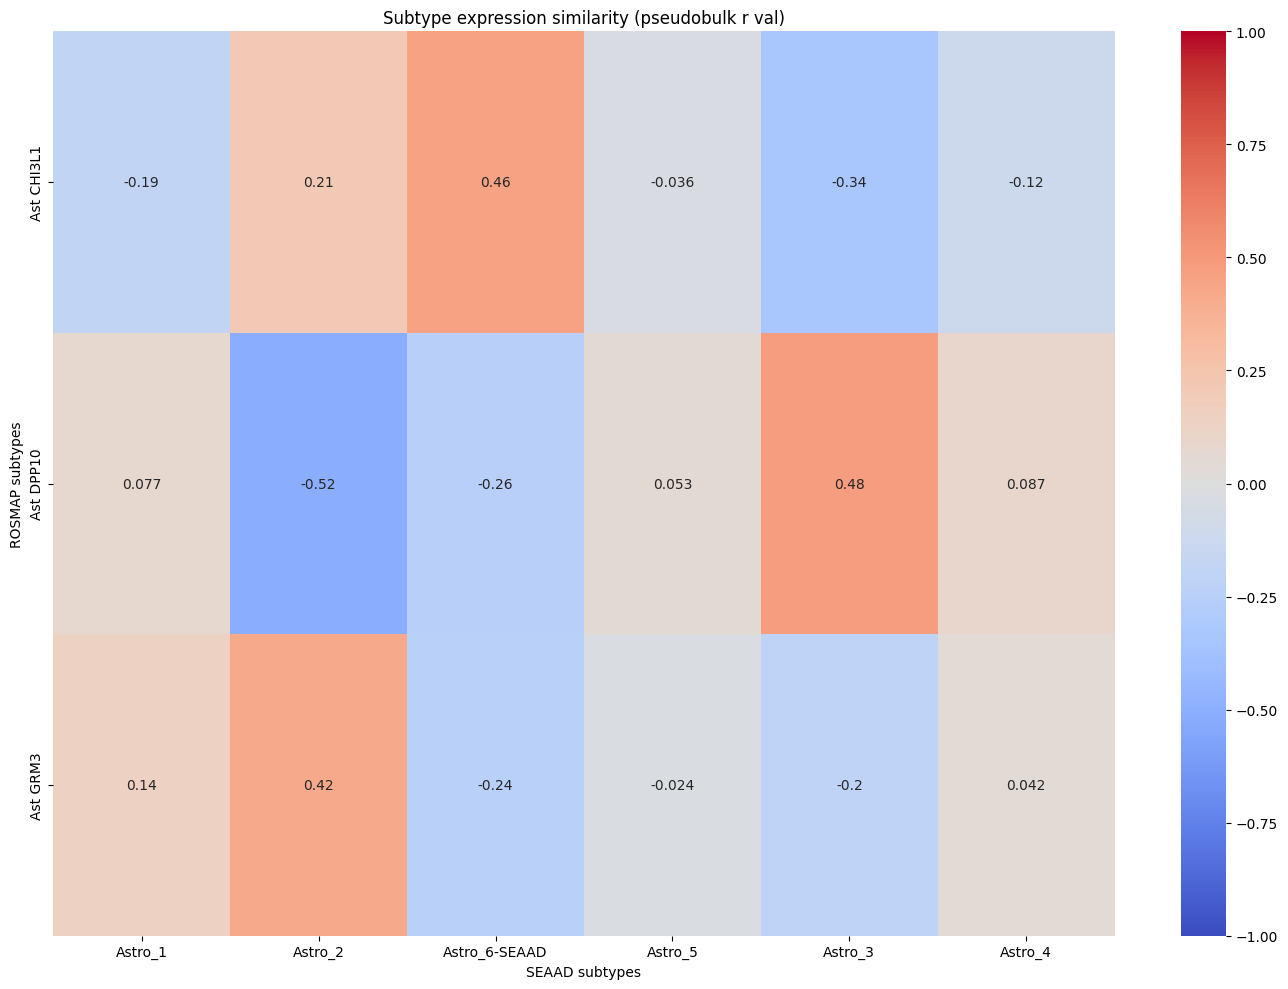

In [124]:
### HVG GENES corr
from sklearn.preprocessing import StandardScaler

ros_z = pd.DataFrame(
    StandardScaler().fit_transform(ros_pb),
    index=ros_pb.index,
    columns=ros_pb.columns,
)

sea_z = pd.DataFrame(
    StandardScaler().fit_transform(sea_pb),
    index=sea_pb.index,
    columns=sea_pb.columns,
)

expr_sim = pd.DataFrame(
    index=ros_z.index,
    columns=sea_z.index,
    dtype=float
)

for r in ros_z.index:
    for s in sea_z.index:
        expr_sim.loc[r, s] = np.corrcoef(
            ros_z.loc[r].values,
            sea_z.loc[s].values
        )[0, 1]
        
plt.figure(figsize=(14,10))
sns.heatmap(expr_sim, vmin=-1, vmax=1, cmap="coolwarm", annot=True)
plt.xlabel("SEAAD subtypes")
plt.ylabel("ROSMAP subtypes")
plt.title("Subtype expression similarity (pseudobulk r val)")
plt.tight_layout()
plt.show()

In [122]:
ros_z.shape

(3, 19)

In [ ]:
breakp

# Try the sc.tl.ingest()
with ROSMAP data as ref

In [2]:
import scvi
import anndata

/opt/anaconda3/envs/label_transfer/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
#rosmap = sc.read_h5ad(r"C:\Users\gabri\Documents\Data_projects\MCcharactertization\ROSMAP\_core_data\scanpy\Astrocytes.h5ad")
rosmap = sc.read_h5ad('/Users/ga0028vi/Documents/MCcharactertization/ROSMAP/_core_data/scanpy/Astrocytes.h5ad')

rosmap.obs['projid'] = rosmap.obs['projid'].astype(str)
rosmap.obs['newdons'] = rosmap.obs['projid']
rosmap.obs['cellsubtypes'] = rosmap.obs['cell_type_high_resolution']
rosmap.obs['cellsubtypes'] = rosmap.obs['cellsubtypes'].str.replace('_', '', regex=True)
rosmap.X = rosmap.layers['counts']

#seaad = sc.read_h5ad(r"C:\Users\gabri\Documents\Data_projects\MCcharactertization\SEAAD_PFC\_core_data\SEAAD_PFC_finalnuclei_Astrocytes.h5ad")
seaad = sc.read_h5ad('/Users/ga0028vi/Documents/MCcharactertization/SEAAD_PFC/_core_data/SEAAD_PFC_finalnuclei_Astrocytes.h5ad')

seaad.obs['Donor ID'] = seaad.obs['Donor ID'].astype(str)
seaad.obs['Donor ID'] = seaad.obs['Donor ID'].str.replace('.', '')

### SEAAD cleanup
cols_to_drop = ['Race (choice=White)',
 'Race (choice=Black/ African American)',
 'Race (choice=Asian)',
 'Race (choice=American Indian/ Alaska Native)',
 'Race (choice=Native Hawaiian or Pacific Islander)',
 'Race (choice=Unknown or unreported)',
 'Race (choice=Other)',
 'specify other race',
 'Hispanic/Latino',
 'Highest level of education',
 'Years of education',
 'PMI',
 'Fresh Brain Weight',
 'Brain pH',
 'Overall AD neuropathological Change',
 'Thal',
 'Braak',
 'CERAD score',
 'Overall CAA Score',
 'Highest Lewy Body Disease',
 'Total Microinfarcts (not observed grossly)',
 'Total microinfarcts in screening sections',
 'Atherosclerosis',
 'Arteriolosclerosis',
 'LATE',
 'Cognitive Status',
 'Last CASI Score',
 'Interval from last CASI in months',
 'Last MMSE Score',
 'Interval from last MMSE in months',
 'Last MOCA Score',
 'Interval from last MOCA in months',
 'APOE Genotype',
 'Primary Study Name',
 'Secondary Study Name',
 'NeuN positive fraction on FANS',
 'RIN',
 'cell_prep_type',
 'facs_population_plan',
 'rna_amplification',
 'sample_name',
 'sample_quantity_count',
 'expc_cell_capture',
 'method',
 'pcr_cycles',
 'percent_cdna_longer_than_400bp',
 'rna_amplification_pass_fail',
 'amplified_quantity_ng',
 'load_name',
 'library_prep',
 'library_input_ng',
 'r1_index',
 'avg_size_bp',
 'quantification_fmol',
 'library_prep_pass_fail',
 'exp_component_vendor_name',
 'batch_vendor_name',
 'experiment_component_failed',
 'alignment',
 'Genome',
 'ar_id',
 'bc',
 'GEX_Estimated_number_of_cells',
 'GEX_number_of_reads',
 'GEX_sequencing_saturation',
 'GEX_Mean_raw_reads_per_cell',
 'GEX_Q30_bases_in_barcode',
 'GEX_Q30_bases_in_read_2',
 'GEX_Q30_bases_in_UMI',
 'GEX_Percent_duplicates',
 'GEX_Q30_bases_in_sample_index_i1',
 'GEX_Q30_bases_in_sample_index_i2',
 'GEX_Reads_with_TSO',
 'GEX_Sequenced_read_pairs',
 'GEX_Valid_UMIs',
 'GEX_Valid_barcodes',
 'GEX_Reads_mapped_to_genome',
 'GEX_Reads_mapped_confidently_to_genome',
 'GEX_Reads_mapped_confidently_to_intergenic_regions',
 'GEX_Reads_mapped_confidently_to_intronic_regions',
 'GEX_Reads_mapped_confidently_to_exonic_regions',
 'GEX_Reads_mapped_confidently_to_transcriptome',
 'GEX_Reads_mapped_antisense_to_gene',
 'GEX_Fraction_of_transcriptomic_reads_in_cells',
 'GEX_Total_genes_detected',
 'GEX_Median_UMI_counts_per_cell',
 'GEX_Median_genes_per_cell',
 'Multiome_Feature_linkages_detected',
 'Multiome_Linked_genes',
 'Multiome_Linked_peaks',
 'ATAC_Confidently_mapped_read_pairs',
 'ATAC_Fraction_of_genome_in_peaks',
 'ATAC_Fraction_of_high_quality_fragments_in_cells',
 'ATAC_Fraction_of_high_quality_fragments_overlapping_TSS',
 'ATAC_Fraction_of_high_quality_fragments_overlapping_peaks',
 'ATAC_Fraction_of_transposition_events_in_peaks_in_cells',
 'ATAC_Mean_raw_read_pairs_per_cell',
 'ATAC_Median_high_quality_fragments_per_cell',
 'ATAC_Non-nuclear_read_pairs',
 'ATAC_Number_of_peaks',
 'ATAC_Percent_duplicates',
 'ATAC_Q30_bases_in_barcode',
 'ATAC_Q30_bases_in_read_1',
 'ATAC_Q30_bases_in_read_2',
 'ATAC_Q30_bases_in_sample_index_i1',
 'ATAC_Sequenced_read_pairs',
 'ATAC_TSS_enrichment_score',
 'ATAC_Unmapped_read_pairs',
 'ATAC_Valid_barcodes',
 'Number of mapped reads',
 'Number of unmapped reads',
 'Number of multimapped reads',
 'Number of reads',
 'Number of UMIs',
 'Genes detected',
 'Doublet score',
 'Fraction mitochondrial UMIs',
 'Used in analysis',
 'Class confidence',
 'Class',
 'Subclass confidence','Supertype confidence',
 'Supertype (non-expanded)','Continuous Pseudo-progression Score','Organism','Neurotypical reference',
 'Brain Region', 'Sex', 'Gender', 'Age at Death',
 'Severely Affected Donor']
seaad.obs = seaad.obs.drop(columns=cols_to_drop, errors="ignore")
del seaad.uns
del seaad.obsm
del seaad.obsp

seaad.X = seaad.layers['UMIs']
#seaad.obs["major_cell_type"] = "OPC"
seaad.obs["cellsubtypes"] = seaad.obs['Supertype']
seaad.obs['newdons'] = seaad.obs['Donor ID']


/opt/anaconda3/envs/label_transfer/lib/python3.12/site-packages/legacy_api_wrap/__init__.py:88: UserWarning: `flavor='seurat_v3'` expects raw count data, but non-integers were found.
  return fn(*args_all, **kw)


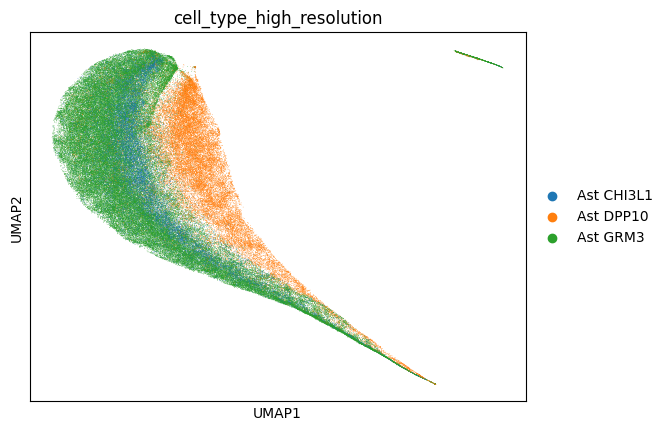

In [4]:
# Test A
adata = rosmap.copy()

label_key = "cell_type_high_resolution"   # your subtype labels

# If X is counts:
sc.pp.normalize_total(adata, target_sum=1e4)
#sc.pp.log1p(adata)

sc.pp.highly_variable_genes(adata, n_top_genes=5000, flavor="seurat_v3")
adata = adata[:, adata.var["highly_variable"]].copy()

#sc.pp.scale(adata, max_value=10)
sc.tl.pca(adata, n_comps=50)

# Try a couple combos; these matter a lot
sc.pp.neighbors(adata, n_neighbors=50, n_pcs=30)
sc.tl.umap(adata, min_dist=0.1)

sc.pl.umap(adata, color=[label_key])


In [5]:
# Test B
adata = rosmap.copy()
label_key = "cell_type_high_resolution"

sc.experimental.pp.highly_variable_genes(
    adata, flavor="pearson_residuals", n_top_genes=5000
)
adata = adata[:, adata.var["highly_variable"]].copy()

sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)
sc.pp.scale(adata, max_value=10)

sc.tl.pca(adata, n_comps=50)
sc.pp.neighbors(adata, n_neighbors=50, n_pcs=30)
sc.tl.umap(adata, min_dist=0.1)

sc.pl.umap(adata, color=[label_key])

ValueError: could not convert integer scalar

In [ ]:
# --- pick reference + query ---
ref = rosmap.copy()
qry = seaad.copy()

# --- make sure same genes in same order ---
genes = ref.var_names.intersection(qry.var_names)
ref = ref[:, genes].copy()
qry = qry[:, genes].copy()

In [132]:
# --- reference preprocessing (must be done on ref) ---
sc.pp.normalize_total(ref)
sc.pp.normalize_total(qry)
sc.pp.log1p(ref)
sc.pp.log1p(qry)
sc.pp.highly_variable_genes(ref, n_top_genes=2000)
ref = ref[:, ref.var["highly_variable"]].copy()
qry = qry[:, ref.var_names].copy()


In [ ]:
# scale + PCA
sc.pp.scale(ref, max_value=10)
sc.pp.scale(qry, max_value=10) #do the same? ingest uses ref PCA loadings so scaling needs to be consistent-ish

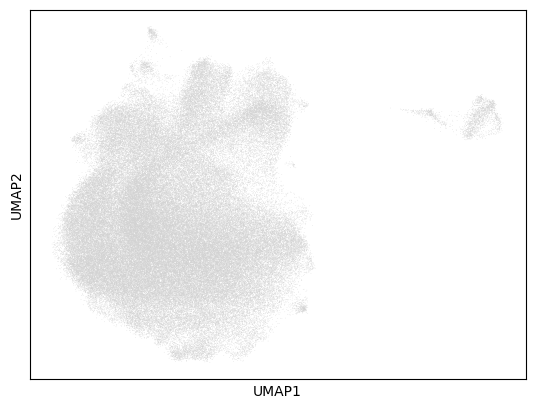

In [133]:
sc.tl.pca(ref, n_comps=50)
sc.pp.neighbors(ref, n_neighbors=30, n_pcs=50)
sc.tl.umap(ref)  # optional, only if you want mapped UMAP

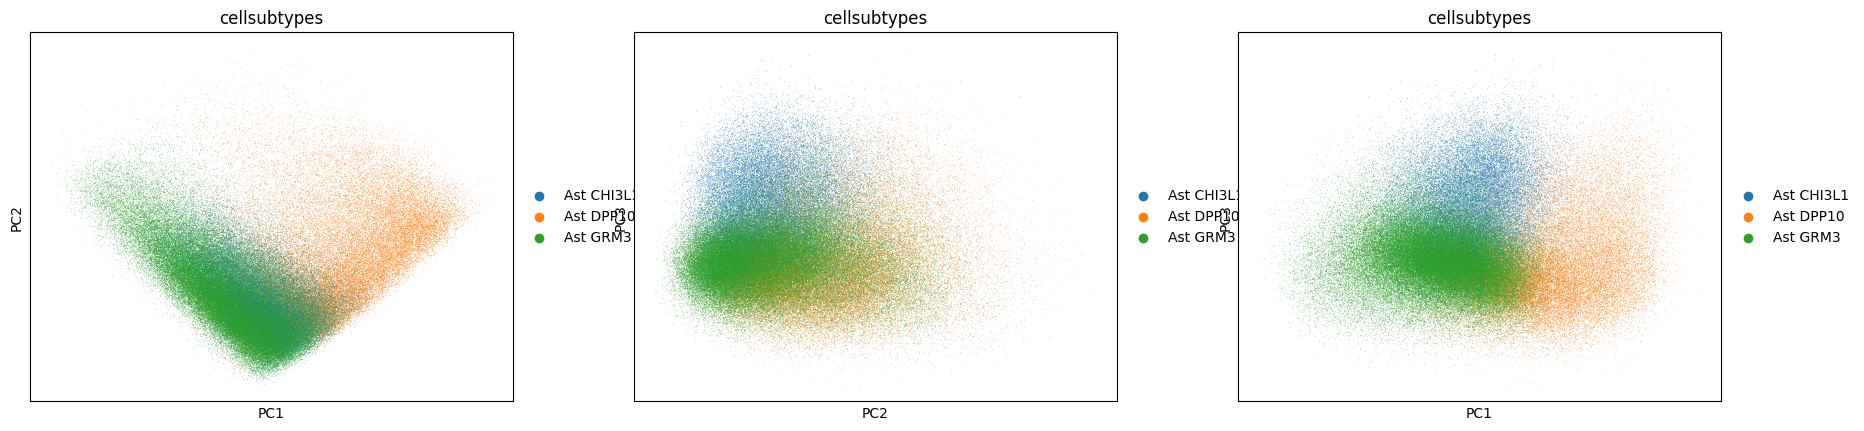

In [137]:
sc.pl.pca(
    ref,
    color="cellsubtypes",  # or whatever the ref label is
    components=["1,2", "2,3", "1,3"]
)

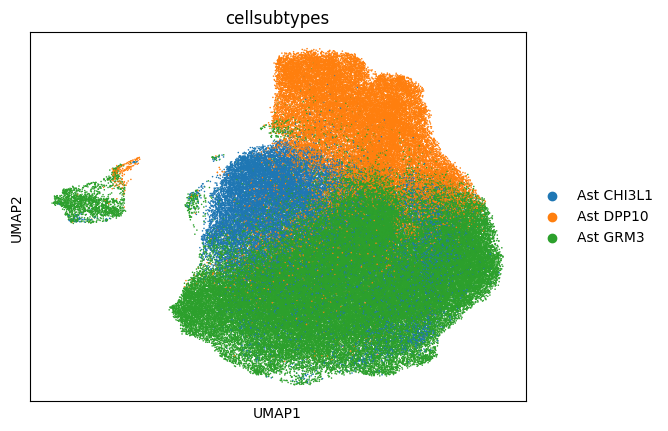

In [145]:
sc.pp.neighbors(ref, n_neighbors=10, n_pcs=10)
sc.tl.umap(ref)
sc.pl.umap(ref, color="cellsubtypes", size=1)


In [147]:
ref.obs['cellsubtypes'].value_counts()

cellsubtypes
Ast GRM3      92527
Ast DPP10     32779
Ast CHI3L1    24252
Name: count, dtype: int64

In [127]:
sc.pp.neighbors(ref, n_neighbors=30, n_pcs=50)
sc.tl.umap(ref)  # optional, only if you want mapped UMAP


# --- label transfer ---
# label must exist in ref.obs
ref.obs["ref_label"] = ref.obs["cellsubtypes"].astype("category")

sc.tl.ingest(qry, ref, obs="ref_label")   # writes predicted labels into qry.obs["ref_label"]
# If ref has umap, qry.obsm["X_umap"] gets mapped too

# --- cluster-level vote in query ---
# assume qry.obs["cluster"] exists (Leiden etc.)
cluster_to_label = (
    qry.obs.groupby("cellsubtypes")["ref_label"]
    .agg(lambda x: x.value_counts().index[0])  # majority vote
)

cluster_to_label

/opt/anaconda3/envs/SEAADpy/lib/python3.12/site-packages/umap/umap_.py:1943: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(f"n_jobs value {self.n_jobs} overridden to 1 by setting random_state. Use no seed for parallelism.")
/var/folders/jz/zwpbs5514b1ds5vjsw00133m0000gp/T/ipykernel_90287/1229564016.py:38: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  qry.obs.groupby("cellsubtypes")["ref_label"]


cellsubtypes
Astro_1            Ast GRM3
Astro_2            Ast GRM3
Astro_6-SEAAD    Ast CHI3L1
Astro_5            Ast GRM3
Astro_3           Ast DPP10
Astro_4           Ast DPP10
Name: ref_label, dtype: category
Categories (3, object): ['Ast CHI3L1', 'Ast DPP10', 'Ast GRM3']

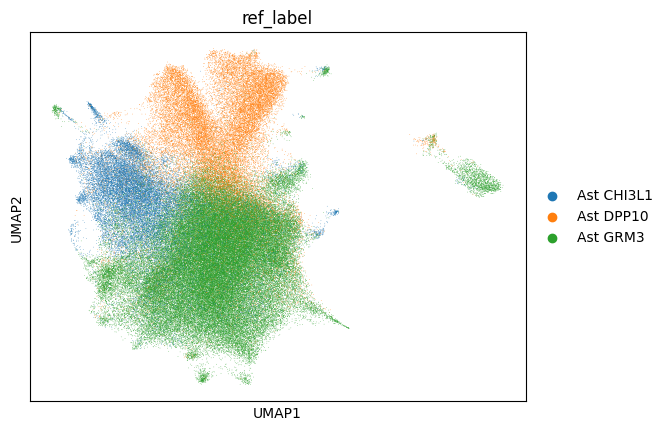

In [128]:
sc.pl.umap(ref, color="ref_label")


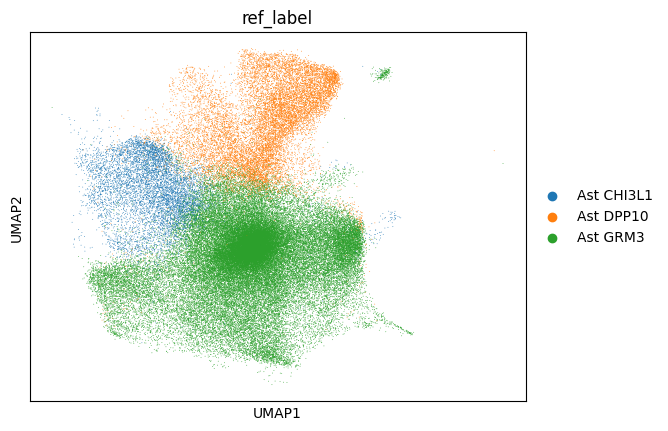

In [129]:
sc.pl.umap(qry, color="ref_label")


### W/ marker genes

In [ ]:
adata = seaad.concatenate(rosmap)
# batch 0 - seaad
# batch  1 - rosmap